In [11]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

In [13]:
data = np.loadtxt("/content/drive/MyDrive/Inverse Kinematics Dataset/robot_inverse_kinematics_dataset.csv", skiprows=1, delimiter=',')
print(data.shape)
print(type(data))

(15000, 9)
<class 'numpy.ndarray'>


In [14]:
# Load data (CSV file)
# data: numpy array, first 6 columns are joint angles, last 3 are xyz
q = data[:, :6]  # Joint angles
xyz = data[:, 6:]  # End-effector positions

# Scale data
scaler_q = MinMaxScaler()
q_scaled = scaler_q.fit_transform(q)

scaler_xyz = MinMaxScaler()
xyz_scaled = scaler_xyz.fit_transform(xyz)

# Split into training and validation sets
q_train, q_val, xyz_train, xyz_val = train_test_split(q_scaled, xyz_scaled, test_size=0.2, random_state=42)


# Print shapes of training and validation sets
print('Training set shapes:')
print('q_train:', q_train.shape)
print('xyz_train:', xyz_train.shape)

print('\nValidation set shapes:')
print('q_val:', q_val.shape)
print('xyz_val:', xyz_val.shape)

Training set shapes:
q_train: (12000, 6)
xyz_train: (12000, 3)

Validation set shapes:
q_val: (3000, 6)
xyz_val: (3000, 3)


In [15]:
# Define and train an LSTM model
model = Sequential()
model.add(LSTM(64, input_shape=(6, 1), return_sequences=True))
model.add(LSTM(64))
model.add(Dense(3))  # Predict xyz

model.compile(loss='mean_squared_error', optimizer='adam')
history = model.fit(q_train.reshape(q_train.shape[0], q_train.shape[1], 1),
                    xyz_train,
                    epochs=100,
                    batch_size=32,
                    validation_data=(q_val.reshape(q_val.shape[0], q_val.shape[1], 1), xyz_val))

Epoch 1/100


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - loss: 0.0646 - val_loss: 0.0334
Epoch 2/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0336 - val_loss: 0.0328
Epoch 3/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0329 - val_loss: 0.0304
Epoch 4/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - loss: 0.0297 - val_loss: 0.0274
Epoch 5/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0260 - val_loss: 0.0248
Epoch 6/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.0243 - val_loss: 0.0237
Epoch 7/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0233 - val_loss: 0.0229
Epoch 8/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - loss: 0.0223 - val_loss: 0.0218
Epoch 9/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0221 - val_loss: 0.0214
Epoch 10/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0215 - val_loss: 0.0211
Epoch 11/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 0.0211 - val_loss: 0.0210
Epoch 12/100
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/s

In [16]:
# Make predictions
xyz_pred_scaled = model.predict(q_val.reshape(q_val.shape[0], q_val.shape[1], 1))

# Inverse scale to original units
xyz_pred = scaler_xyz.inverse_transform(xyz_pred_scaled)
xyz_true = scaler_xyz.inverse_transform(xyz_val)

# Compute metrics
mse = mean_squared_error(xyz_true, xyz_pred)
mae = mean_absolute_error(xyz_true, xyz_pred)
r2 = r2_score(xyz_true, xyz_pred)

94/94 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step


In [17]:
# Compute end-effector Euclidean error
def fk(q_input):

    return np.zeros((q_input.shape[0], 3))

# Compute Euclidean distance between predicted xyz and true xyz
ee_error = np.linalg.norm(xyz_true - xyz_pred, axis=1)  # per-sample Euclidean distance
mean_ee_error = np.mean(ee_error)
max_ee_error = np.max(ee_error)


In [18]:
# Print metrics
print(f"Validation Metrics:")
print(f"MSE: {mse:.4f}")
print(f"MAE: {mae:.4f}")
print(f"R²: {r2:.4f}")
print(f"End-Effector Error (mean): {mean_ee_error:.6f}")
print(f"End-Effector Error (max): {max_ee_error:.6f}")

Validation Metrics:
MSE: 0.0000
MAE: 0.0045
R²: 0.9970
End-Effector Error (mean): 0.009000
End-Effector Error (max): 0.046402


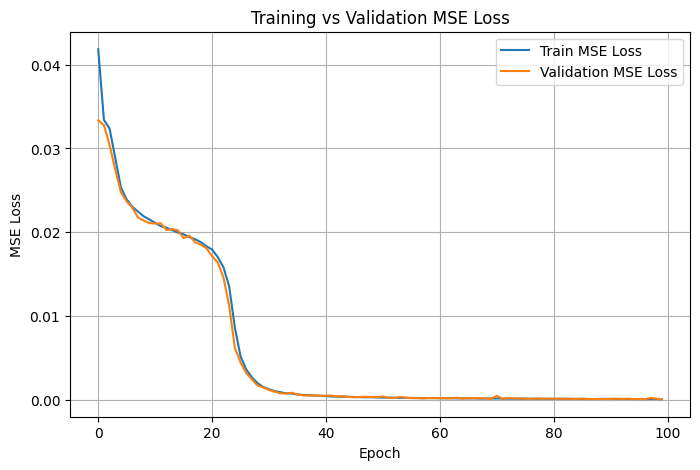

In [19]:
# Plot Training & Validation MSE Loss
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label='Train MSE Loss')
plt.plot(history.history['val_loss'], label='Validation MSE Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('Training vs Validation MSE Loss')
plt.legend()
plt.grid(True)
plt.show()